# Single-Trace Attack on Falcon-1024

The attacker has power traces of the victim device and a set of **templates** - one per
possible coefficient value (-10 .. +10). Goal: recover the secret key `f, g`.

Templates are already trained; we only run the attack.


In [1]:
import os, sys, numpy as np, matplotlib.pyplot as plt, trsfile
sys.path.insert(0, os.path.abspath(os.path.join('..', 'template_attack'))); import falcon_keymath as km

T = np.load(os.path.join('..', 'template_attack', 'templates.npz'))
candidates = T['classes'] - 10; pois, mu, sd, W, b = T['pois'], T['mu'], T['sd'], T['W_lda'], T['b_lda']
K = np.load('nb_falcon1024.npz'); f_true, g_true = K['f'].astype(int), K['g'].astype(int); h = K['h'].astype(np.uint32)
N = km.N

traces = {c: [] for c in candidates}
with trsfile.trs_open(r'C:/Users/mervkara/Inspector/data/falcon_gui_split_leak1/split_TEST.trs', 'r') as ts:
    for i in range(len(ts)):
        v = int(ts[i].parameters['f0_class'].value[0]) - 10
        traces[v].append(np.asarray(ts[i].samples)[pois])
traces = {c: np.array(v, float) for c, v in traces.items()}
print('templates for', len(candidates), 'values; victim traces loaded')


templates for 21 values; victim traces loaded


## 1. A victim power trace


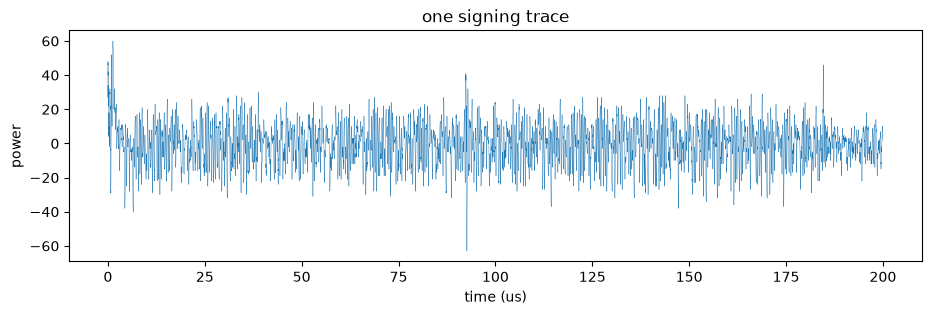

In [2]:
example = np.load('nb_corr_full.npz')['example'].astype(float)
plt.figure(figsize=(11, 3)); plt.plot(np.arange(len(example)) / 1000.0, example, lw=.3)
plt.xlabel('time (us)'); plt.ylabel('power'); plt.title('one signing trace'); plt.show()


## 2. Attack one coefficient

Take the victim's measurement of `f[0]`, score it against every template, and rank the
candidate values. The best score is the prediction; the gap to the runner-up is the confidence.


In [3]:
rng = np.random.default_rng(0)
def measure(value, n=45): return traces[int(value)][rng.choice(len(traces[int(value)]), n, replace=False)].mean(0)
def scores(trace): return ((trace - mu) / sd) @ W.T + b

s = scores(measure(f_true[0])); rank = np.argsort(s)[::-1]
print('candidate  score'); [print(f'  {candidates[j]:+d}   {s[j]:8.2f}') for j in rank[:5]]
print(f'\npredicted f[0] = {candidates[rank[0]]:+d}   confidence {s[rank[0]] - s[rank[1]]:.2f}')


candidate  score
  +2      34.08
  +1      33.86
  +5      30.86
  +0      30.58
  +6      30.50

predicted f[0] = +2   confidence 0.22


## 3. A few more coefficients


In [4]:
for i in range(10):
    s = scores(measure(f_true[i])); r = np.argsort(s)[::-1]
    print(f'f[{i:>2}]  predicted {candidates[r[0]]:+d}   (secret {f_true[i]:+d})   confidence {s[r[0]] - s[r[1]]:.2f}')


f[ 0]  predicted +2   (secret +2)   confidence 0.61
f[ 1]  predicted +0   (secret +0)   confidence 4.27
f[ 2]  predicted +1   (secret +1)   confidence 0.44
f[ 3]  predicted -2   (secret -2)   confidence 0.46
f[ 4]  predicted +3   (secret +3)   confidence 1.96
f[ 5]  predicted +5   (secret +5)   confidence 0.31
f[ 6]  predicted -1   (secret -1)   confidence 5.27
f[ 7]  predicted -3   (secret -3)   confidence 0.39
f[ 8]  predicted +0   (secret +0)   confidence 3.51
f[ 9]  predicted +5   (secret +5)   confidence 0.26


## 4. Recover the full key

The template reads every coefficient (~98% correct). We keep the 1030 most-confident reads and
solve the public relation `H*f = g (mod 12289)` for the rest. A Falcon coefficient must be in
**[-15, 15]**, so that bound is our check: if the solved key stays in range, it is correct.


In [5]:
reads = []
for arr, tag in ((f_true, 'f'), (g_true, 'g')):
    for i, v in enumerate(arr):
        s = scores(measure(v)); r = np.argsort(s)[::-1]
        reads.append((s[r[0]] - s[r[1]], tag, i, int(candidates[r[0]])))
reads.sort(reverse=True); top = reads[:1030]
kf = {i: v for _, t, i, v in top if t == 'f'}; kg = {i: v for _, t, i, v in top if t == 'g'}
ff, gg = km.solve_completion_fast(h, kf, kg)
fr = np.array([km.to_signed(v) for v in ff]); gr = np.array([km.to_signed(v) for v in gg])

in_range = bool(np.all(np.abs(fr) <= 15) and np.all(np.abs(gr) <= 15))
print('recovered f[0:16] :', fr[:16].tolist())
print('secret    f[0:16] :', f_true[:16].tolist())
print('\nall coefficients in [-15,15] :', in_range)
print('secret key recovered         :', np.array_equal(fr, f_true) and np.array_equal(gr, g_true))


recovered f[0:16] : [2, 0, 1, -2, 3, 5, -1, -3, 0, 5, 0, 4, -2, 0, 3, 1]
secret    f[0:16] : [2, 0, 1, -2, 3, 5, -1, -3, 0, 5, 0, 4, -2, 0, 3, 1]

all coefficients in [-15,15] : True
secret key recovered         : True
